<a href="https://colab.research.google.com/github/Aldyth11/Machine-Learning/blob/main/JS15/JS15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Klasifikasi Gambar (Day vs Night) dengan Neural Network

### Langkah 1: Import Library dan Mount Google Drive

In [8]:
import os
import requests
import zipfile
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Langkah 2: Unduh dan Ekstrak Dataset GitBook

In [2]:
url = "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc"
headers = {'User-Agent': 'Mozilla/5.0'}

response = requests.get(url, headers=headers)
if response.status_code == 200:
    with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
        zip_ref.extractall("/content/images")
    print("Dataset berhasil diunduh dan diekstrak ke /content/images")
else:
    print(f"Gagal mengunduh dataset. Status code: {response.status_code}")

Dataset berhasil diunduh dan diekstrak ke /content/images


### Langkah 3: Load Dataset

In [16]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    # Membaca seluruh file gambar di dalam folder kategori (day/night)
    for file in p.glob('*/*'):
        if file.is_file() and file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            label = file.parent.name
            img = cv2.imread(str(file))
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img_list.append((img, label))
    return img_list

# Penanganan otomatis jika hasil ekstraksi zip membentuk folder /content/images/images/...
train_dir = "/content/images/images/training" if os.path.exists("/content/images/images/training") else "/content/images/training"
test_dir  = "/content/images/images/test" if os.path.exists("/content/images/images/test") else "/content/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

summary_df = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'Jumlah Gambar': [len(train_img), len(test_img)]
})
display(summary_df)

,Dataset,Jumlah Gambar
0,Training,240
1,Testing,160


### Langkah 4: Preprocessing (Resize & Label Encoding)

In [18]:
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

### Langkah 5: Ekstraksi Fitur HOG (Histogram of Oriented Gradients)

In [19]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

### Langkah 6: Normalisasi Fitur

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

scaled_df = pd.DataFrame(X_train_scaled)
display(scaled_df.head())

,0,1,2,3,4,5,6,7,8,9,...,34586,34587,34588,34589,34590,34591,34592,34593,34594,34595
0,0.490316,-0.215460,0.646694,0.848295,0.380300,0.130575,0.554509,-0.270593,3.100322,-1.065453,...,-1.009810,0.402095,-0.534041,0.444488,-0.871959,0.751274,1.988724,1.780863,0.816358,-0.896087
1,0.086102,1.692486,0.733463,-0.405656,-0.529208,1.404752,0.151760,2.333269,1.615925,0.047008,...,0.362613,0.583028,-0.797045,1.575626,1.945923,0.513768,0.076407,-0.036864,0.329226,-0.896087
2,0.646130,-0.874267,0.027758,0.829610,0.769655,1.317927,0.029233,0.577674,-0.749428,0.258717,...,-1.195180,-1.728166,-0.806417,0.053734,0.124517,2.417563,0.087208,-1.106923,-0.906067,-0.854665
3,-1.628749,-0.874267,-1.130267,-0.978712,-1.552668,-0.927287,-1.071237,-0.881067,-0.749428,-1.774018,...,1.675283,-1.141996,-0.859408,-0.930664,-0.816344,-1.430738,-0.758483,-0.815097,-0.986090,-0.811709
4,0.481260,-0.387170,1.677969,0.571698,0.700670,2.262143,-0.373413,-0.881067,-0.749428,0.569950,...,-0.026662,0.945618,1.193069,-0.966068,-0.996740,-0.536182,-0.736421,1.206960,0.340557,0.388961


### Langkah 7: Split Data Training & Validation

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

### Langkah 8: Konversi Label ke Numpy Array

In [22]:
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

### Langkah 9: Membangun Arsitektur Model Neural Network

In [23]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 10: Training Model

In [24]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 360ms/step - accuracy: 0.8385 - loss: 0.4202 - val_accuracy: 0.9792 - val_loss: 0.1862
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.9896 - loss: 0.0144 - val_accuracy: 0.9583 - val_loss: 0.1835
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.9948 - loss: 0.0044 - val_accuracy: 0.9792 - val_loss: 0.1635
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 1.0000 - loss: 1.3665e-04 - val_accuracy: 0.9792 - val_loss: 0.1761
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - accuracy: 1.0000 - loss: 6.1461e-05 - val_accuracy: 0.9792 - val_loss: 0.1836
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 1.0000 - loss: 3.6394e-05 - val_accuracy: 0.9792 - val_loss: 0.1887
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 1.0000 - loss: 1.8571e-05 - val_accuracy: 0.9792 - val_loss: 0.1918
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 1.0000 - loss: 1.2340e-05 - val_accuracy: 0

### Langkah 11: Evaluasi Model

In [25]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8625 - loss: 1.1765
Akurasi Test: 0.862500011920929


### Langkah 12: Prediksi dan Laporan Klasifikasi

In [26]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

report_dict = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df)

cm_df = pd.DataFrame(confusion_matrix(y_test, y_pred),
                     index=['Actual Night (0)', 'Actual Day (1)'],
                     columns=['Pred Night (0)', 'Pred Day (1)'])
display(cm_df)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


,precision,recall,f1-score,support
0,0.853659,0.8750,0.864198,80.0000
1,0.871795,0.8500,0.860759,80.0000
accuracy,0.862500,0.8625,0.862500,0.8625
macro avg,0.862727,0.8625,0.862479,160.0000
weighted avg,0.862727,0.8625,0.862479,160.0000


,Pred Night (0),Pred Day (1)
Actual Night (0),70,10
Actual Day (1),12,68


### Langkah 13: Visualisasi History Training

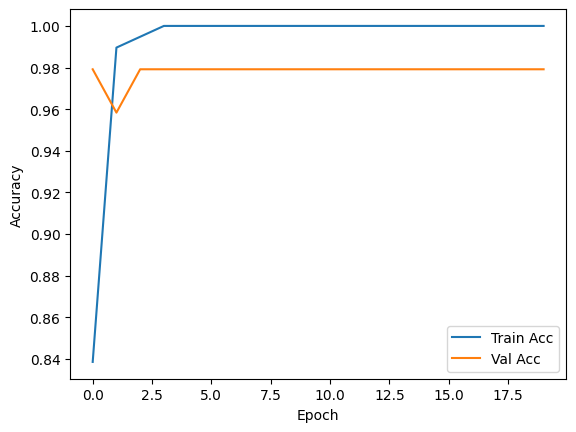

In [27]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Langkah 14: Menyimpan Model dan Scaler

In [28]:
import pickle

model.save('day_night_model.h5')
print("Model berhasil disimpan sebagai: day_night_model.h5")

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan sebagai: scaler.pkl")

Model berhasil disimpan sebagai: day_night_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
